In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
df=pd.read_csv(r"C:\Users\RAVI\Downloads\security_incident_alert_analysis_messy task2.csv")
df.head(20)

,Incident ID,Timestamp,Alert Type,Severity,Source System,Status,Resolution Time,Assigned Team
0,INC-10001,2026-09-06 07:53:23,Endpoint Anomaly,Low,Endpoint Detection,Resolved,623.0,Cloud Security
1,INC-10002,2026-01-13 08:14:09,Endpoint Anomaly,Low,Database Monitor,In Progress,NaN,SOC Level 1
2,INC-10003,2026-08-06 23:10:59,Failed Login,Low,SIEM,Resolved,335.0,Cloud Security
3,INC-10004,2026-05-13 03:21:52,Privilege Escalation,Low,Endpoint Detection,In Progress,NaN,SOC Level 2
4,INC-10005,2026-05-28 13:10:44,Endpoint Anomaly,Low,ENDPOINT DETECTION,Closed,1307.0,NaN
5,INC-10006,2026-01-31 14:28:15,Failed Login,Medium,Email Gateway,Closed,1072.0,Endpoint Security
6,INC-10007,2026-01-31 23:42:54,Phishing Email,High,VPN,Closed,NaN,Identity Security
7,INC-10008,2026-03-23 08:44:49,Endpoint Anomaly,Medium,Email Gateway,Resolved,452.0,Incident Response
8,INC-10009,2026-06-29 12:34:38,Endpoint Anomaly,NaN,Email Gateway,Escalated,NaN,Identity Security
9,INC-10010,2026-01-22 17:22:46,NaN,Low,Cloud Security,Open,NaN,Endpoint Security


In [3]:
print("size of dataset",df.size)
print()
print("shape of dataset",df.shape)
print()
print("data type",df.dtypes)
print()
print("information of dataset",df.info())

size of dataset 8160

shape of dataset (1020, 8)

data type Incident ID        object
Timestamp          object
Alert Type         object
Severity           object
Source System      object
Status             object
Resolution Time    object
Assigned Team      object
dtype: object

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1020 entries, 0 to 1019
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   Incident ID      1020 non-null   object
 1   Timestamp        996 non-null    object
 2   Alert Type       995 non-null    object
 3   Severity         1001 non-null   object
 4   Source System    990 non-null    object
 5   Status           1000 non-null   object
 6   Resolution Time  530 non-null    object
 7   Assigned Team    983 non-null    object
dtypes: object(8)
memory usage: 63.9+ KB
information of dataset None


## find the numeric value 

In [4]:
df.describe()

,Incident ID,Timestamp,Alert Type,Severity,Source System,Status,Resolution Time,Assigned Team
count,1020,996,995,1001,990,1000,530,983
unique,1000,988,25,14,25,17,406,23
top,INC-10661,2026-08-11 08:26:49,Policy Violation,Medium,Email Gateway,Resolved,6.0,Email Security
freq,2,2,117,351,108,391,4,116


## find missing value

In [5]:
print("total missing value ",df.isna().sum().sum())
print()
print("column wise missing value",df.isna().sum())

total missing value  645

column wise missing value Incident ID          0
Timestamp           24
Alert Type          25
Severity            19
Source System       30
Status              20
Resolution Time    490
Assigned Team       37
dtype: int64


## percentage of missing value 

In [6]:
(df.isna().sum()/len(df))*100

Incident ID         0.000000
Timestamp           2.352941
Alert Type          2.450980
Severity            1.862745
Source System       2.941176
Status              1.960784
Resolution Time    48.039216
Assigned Team       3.627451
dtype: float64

## non missing value 

In [7]:
print("non missing value in dataset",df.notna().sum())

non missing value in dataset Incident ID        1020
Timestamp           996
Alert Type          995
Severity           1001
Source System       990
Status             1000
Resolution Time     530
Assigned Team       983
dtype: int64


## find the duplicate value overall dataset

In [8]:
df.duplicated().sum()

np.int64(17)

## display the duplicated value

In [9]:
df[df.duplicated(keep=False)]

,Incident ID,Timestamp,Alert Type,Severity,Source System,Status,Resolution Time,Assigned Team
76,INC-10077,NaN,Data Exfiltration,Medium,IDS/IPS,Resolved,13.0,SOC Level 2
136,INC-10137,NaN,Endpoint Anomaly,Medium,Cloud Security,Escalated,NaN,Incident Response
280,INC-10281,2026-08-13 06:27:19,Endpoint Anomaly,Medium,Email Gateway,Resolved,2027.0,Cloud Security
319,INC-10320,2026-05-08 23:33:05,Brute Force Attempt,Medium,Email Gateway,Resolved,454.0,Email Security
513,INC-10514,NaN,Failed Login,High,Cloud Security,Resolved,382.0,Cloud Security
521,INC-10522,NaN,Endpoint Anomaly,High,Web Proxy,Open,NaN,NaN
626,INC-10627,NaN,Endpoint Anomaly,Medium,VPN,In Progress,NaN,Email Security
636,INC-10637,2026-03-27 17:17:07,Suspicious Network Traffic,Medium,IDS/IPS,Open,NaN,SOC Level 2
660,INC-10661,NaN,Malware Detection,Low,Endpoint Detection,Closed,863.0,SOC Level 1
737,INC-10738,NaN,Brute Force Attempt,Medium,IDS/IPS,In Progress,NaN,Network Security


# drop duplicate value in dataset

In [10]:
df = df.drop_duplicates()
df.duplicated().sum()

np.int64(0)

## check first column

In [11]:
df["Incident ID"].dtype

dtype('O')

In [12]:
df["Incident ID"].nunique()

1000

In [13]:
df["Incident ID"].isna().sum()

np.int64(0)

In [14]:
df["Incident ID"].duplicated().sum()

np.int64(3)

In [15]:
df[df["Incident ID"].duplicated(keep=False)]

,Incident ID,Timestamp,Alert Type,Severity,Source System,Status,Resolution Time,Assigned Team
411,INC-10412,NaN,Phishing Email,Critical,SIEM,Escalated,NaN,NETWORK SECURITY
678,INC-10679,NaN,Brute Force Attempt,Low,Database Monitor,OPEN,NaN,Endpoint Security
740,INC-10741,NaN,Failed Login,Critical,Firewall,Resolved,2953.0,Threat Intelligence
1002,INC-10741,NaN,Failed Login,Critical,Firewall,Resolved,2953.0,Threat Intelligence
1004,INC-10412,NaN,Phishing Email,Critical,SIEM,Escalated,NaN,Network Security
1005,INC-10679,NaN,Brute Force Attempt,Low,Database Monitor,Open,NaN,Endpoint Security


In [16]:
df = df.drop_duplicates(subset=["Incident ID"])
df["Incident ID"].duplicated().sum()

np.int64(0)

## check second column Timestamp

In [17]:
df["Timestamp"].dtype

dtype('O')

In [18]:
df["Timestamp"] = pd.to_datetime(
    df["Timestamp"], errors="coerce"
)
print(df["Timestamp"].dtype)

datetime64[ns]


In [19]:
df["Timestamp"].nunique()

988

In [20]:
print("Total unique dates:", df["Timestamp"].dt.date.nunique())

Total unique dates: 292


In [21]:
(df["Timestamp"].dt.date.value_counts().sort_index().head(50))

Timestamp
2026-01-01    2
2026-01-02    3
2026-01-03    4
2026-01-04    1
2026-01-05    3
2026-01-06    2
2026-01-07    3
2026-01-08    2
2026-01-09    2
2026-01-10    1
2026-01-11    3
2026-01-12    3
2026-01-13    8
2026-01-14    1
2026-01-15    4
2026-01-17    1
2026-01-18    5
2026-01-19    1
2026-01-20    5
2026-01-21    5
2026-01-22    3
2026-01-23    2
2026-01-24    7
2026-01-25    5
2026-01-26    4
2026-01-27    6
2026-01-28    1
2026-01-29    4
2026-01-30    6
2026-01-31    5
2026-02-01    2
2026-02-02    3
2026-02-03    6
2026-02-04    5
2026-02-05    9
2026-02-06    5
2026-02-07    2
2026-02-08    2
2026-02-09    3
2026-02-10    2
2026-02-11    4
2026-02-12    1
2026-02-13    3
2026-02-14    5
2026-02-15    1
2026-02-16    2
2026-02-17    5
2026-02-18    1
2026-02-19    2
2026-02-20    4
Name: count, dtype: int64

In [22]:
print("missing value ",df["Timestamp"].isna().sum())

missing value  12


In [23]:
df[df["Timestamp"].isna()]

,Incident ID,Timestamp,Alert Type,Severity,Source System,Status,Resolution Time,Assigned Team
76,INC-10077,NaT,Data Exfiltration,Medium,IDS/IPS,Resolved,13.0,SOC Level 2
136,INC-10137,NaT,Endpoint Anomaly,Medium,Cloud Security,Escalated,NaN,Incident Response
411,INC-10412,NaT,Phishing Email,Critical,SIEM,Escalated,NaN,NETWORK SECURITY
513,INC-10514,NaT,Failed Login,High,Cloud Security,Resolved,382.0,Cloud Security
521,INC-10522,NaT,Endpoint Anomaly,High,Web Proxy,Open,NaN,NaN
626,INC-10627,NaT,Endpoint Anomaly,Medium,VPN,In Progress,NaN,Email Security
660,INC-10661,NaT,Malware Detection,Low,Endpoint Detection,Closed,863.0,SOC Level 1
678,INC-10679,NaT,Brute Force Attempt,Low,Database Monitor,OPEN,NaN,Endpoint Security
737,INC-10738,NaT,Brute Force Attempt,Medium,IDS/IPS,In Progress,NaN,Network Security
740,INC-10741,NaT,Failed Login,Critical,Firewall,Resolved,2953.0,Threat Intelligence


In [24]:
df["Timestamp"] = df["Timestamp"].ffill()
df["Timestamp"].isna().sum()

np.int64(0)

In [25]:
df["Timestamp"].duplicated().sum()

np.int64(12)

In [26]:
df[df["Timestamp"].duplicated(keep=False)]

,Incident ID,Timestamp,Alert Type,Severity,Source System,Status,Resolution Time,Assigned Team
75,INC-10076,2026-01-30 12:20:18,Brute Force Attempt,Medium,Endpoint Detection,Closed,1194.0,SOC Level 1
76,INC-10077,2026-01-30 12:20:18,Data Exfiltration,Medium,IDS/IPS,Resolved,13.0,SOC Level 2
135,INC-10136,2026-07-11 07:35:39,Endpoint Anomaly,Low,SIEM,In Progress,NaN,Cloud Security
136,INC-10137,2026-07-11 07:35:39,Endpoint Anomaly,Medium,Cloud Security,Escalated,NaN,Incident Response
410,INC-10411,2026-03-03 23:48:39,Suspicious Network Traffic,Low,Database Monitor,Resolved,1316.0,Cloud Security
411,INC-10412,2026-03-03 23:48:39,Phishing Email,Critical,SIEM,Escalated,NaN,NETWORK SECURITY
512,INC-10513,2026-02-26 20:48:41,Policy Violation,High,Endpoint Detection,Resolved,42.0,Threat Intelligence
513,INC-10514,2026-02-26 20:48:41,Failed Login,High,Cloud Security,Resolved,382.0,Cloud Security
520,INC-10521,2026-01-29 07:17:53,Suspicious Network Traffic,High,SIEM,In Progress,NaN,Threat Intelligence
521,INC-10522,2026-01-29 07:17:53,Endpoint Anomaly,High,Web Proxy,Open,NaN,NaN


## Alter type column

In [27]:
df["Alert Type"].dtype

dtype('O')

In [28]:
df["Alert Type"].unique()

array(['Endpoint Anomaly', 'Failed Login', 'Privilege Escalation',
       'Phishing Email', nan, 'Malware Detection',
       'Suspicious Network Traffic', 'Policy Violation',
       'Data Exfiltration', 'Unauthorized Access', 'Brute Force Attempt',
       'data exfiltration', 'privilege escalation',
       'PRIVILEGE ESCALATION', 'POLICY VIOLATION', 'FAILED LOGIN',
       'BRUTE FORCE ATTEMPT', ' Brute Force Attempt ', 'phishing email',
       'SUSPICIOUS NETWORK TRAFFIC', 'failed login', 'endpoint anomaly',
       'UNAUTHORIZED ACCESS', ' Privilege Escalation ',
       'policy violation', ' Suspicious Network Traffic '], dtype=object)

In [29]:
df["Alert Type"].nunique()

25

In [30]:
df["Alert Type"].isna().sum()

np.int64(25)

In [31]:
df["Alert Type"]=df["Alert Type"].str.strip().str.upper()
df["Alert Type"]=df["Alert Type"].fillna("UNKNOWN")

In [32]:
df["Alert Type"].unique()

array(['ENDPOINT ANOMALY', 'FAILED LOGIN', 'PRIVILEGE ESCALATION',
       'PHISHING EMAIL', 'UNKNOWN', 'MALWARE DETECTION',
       'SUSPICIOUS NETWORK TRAFFIC', 'POLICY VIOLATION',
       'DATA EXFILTRATION', 'UNAUTHORIZED ACCESS', 'BRUTE FORCE ATTEMPT'],
      dtype=object)

In [33]:
df["Alert Type"].nunique()

11

In [34]:
df["Alert Type"].value_counts()

Alert Type
POLICY VIOLATION              120
ENDPOINT ANOMALY              108
MALWARE DETECTION             108
BRUTE FORCE ATTEMPT            99
DATA EXFILTRATION              98
PRIVILEGE ESCALATION           97
FAILED LOGIN                   87
SUSPICIOUS NETWORK TRAFFIC     87
UNAUTHORIZED ACCESS            86
PHISHING EMAIL                 85
UNKNOWN                        25
Name: count, dtype: int64

In [35]:
df["Alert Type"].isna().sum()

np.int64(0)

In [36]:
df.columns

Index(['Incident ID', 'Timestamp', 'Alert Type', 'Severity', 'Source System',
       'Status', 'Resolution Time', 'Assigned Team'],
      dtype='object')

## severity column

In [37]:
df["Severity"].dtype

dtype('O')

In [38]:
df["Severity"].unique()

array(['Low', 'Medium', 'High', nan, 'Critical', ' Low ', 'LOW', 'high',
       'low', 'critical', ' Medium ', 'MEDIUM', 'medium', 'HIGH',
       ' Critical '], dtype=object)

In [39]:
df["Severity"].nunique()

14

In [40]:
df["Severity"].isna().sum()

np.int64(18)

In [41]:
df["Severity"]=df["Severity"].str.strip().str.upper()
df["Severity"]=df["Severity"].fillna("UNKNOWN")

In [42]:
df["Severity"].unique()

array(['LOW', 'MEDIUM', 'HIGH', 'UNKNOWN', 'CRITICAL'], dtype=object)

In [43]:
df["Severity"].nunique()

5

In [44]:
df["Severity"].value_counts()

Severity
MEDIUM      350
LOW         339
HIGH        207
CRITICAL     86
UNKNOWN      18
Name: count, dtype: int64

In [45]:
df.columns

Index(['Incident ID', 'Timestamp', 'Alert Type', 'Severity', 'Source System',
       'Status', 'Resolution Time', 'Assigned Team'],
      dtype='object')

## source system column

In [46]:
df["Source System"].dtype

dtype('O')

In [47]:
df["Source System"].unique()

array(['Endpoint Detection', 'Database Monitor', 'SIEM',
       'ENDPOINT DETECTION', 'Email Gateway', 'VPN', 'Cloud Security',
       'Identity Provider', 'Web Proxy', 'IDS/IPS', 'Firewall', nan,
       ' Database Monitor ', 'web proxy', 'ids/ips', 'CLOUD SECURITY',
       ' IDS/IPS ', 'IDENTITY PROVIDER', 'cloud security',
       'DATABASE MONITOR', ' VPN ', 'siem', ' Web Proxy ',
       'identity provider', ' Endpoint Detection ', ' Firewall '],
      dtype=object)

In [48]:
df["Source System"].nunique()

25

In [49]:
df["Source System"]=df["Source System"].str.strip().str.upper()
df["Source System"]=df["Source System"].fillna("UNKNOWN")

In [50]:
df["Source System"].unique()

array(['ENDPOINT DETECTION', 'DATABASE MONITOR', 'SIEM', 'EMAIL GATEWAY',
       'VPN', 'CLOUD SECURITY', 'IDENTITY PROVIDER', 'WEB PROXY',
       'IDS/IPS', 'FIREWALL', 'UNKNOWN'], dtype=object)

In [51]:
df["Source System"].nunique()

11

In [52]:
df["Source System"].value_counts()

Source System
EMAIL GATEWAY         106
ENDPOINT DETECTION    105
SIEM                  102
IDENTITY PROVIDER     102
WEB PROXY             102
IDS/IPS               101
DATABASE MONITOR       94
VPN                    93
CLOUD SECURITY         84
FIREWALL               81
UNKNOWN                30
Name: count, dtype: int64

In [53]:
df.columns

Index(['Incident ID', 'Timestamp', 'Alert Type', 'Severity', 'Source System',
       'Status', 'Resolution Time', 'Assigned Team'],
      dtype='object')

# Status column

In [54]:
df["Status"].dtype

dtype('O')

In [55]:
df["Status"].unique()

array(['Resolved', 'In Progress', 'Closed', 'Escalated', 'Open', nan,
       'CLOSED', 'RESOLVED', ' Resolved ', 'resolved', 'closed',
       'in progress', ' In Progress ', 'OPEN', 'IN PROGRESS', ' Closed ',
       ' Escalated '], dtype=object)

In [56]:
df["Status"]=df["Status"].str.strip().str.upper()
df["Status"]=df["Status"].fillna("UNKNOWN")

In [57]:
df["Status"].unique()

array(['RESOLVED', 'IN PROGRESS', 'CLOSED', 'ESCALATED', 'OPEN',
       'UNKNOWN'], dtype=object)

In [58]:
df["Status"].value_counts()

Status
RESOLVED       393
IN PROGRESS    200
CLOSED         163
OPEN           158
ESCALATED       66
UNKNOWN         20
Name: count, dtype: int64

## Assigned Team

In [59]:
df["Assigned Team"].dtype

dtype('O')

In [60]:
df["Assigned Team"].unique()

array(['Cloud Security', 'SOC Level 1', 'SOC Level 2', nan,
       'Endpoint Security', 'Identity Security', 'Incident Response',
       'Email Security', 'Threat Intelligence', 'Network Security',
       'THREAT INTELLIGENCE', 'cloud security', ' Cloud Security ',
       'email security', 'CLOUD SECURITY', 'NETWORK SECURITY',
       ' Identity Security ', ' Network Security ', 'threat intelligence',
       'network security', ' SOC Level 1 ', ' Email Security ',
       'EMAIL SECURITY', ' Threat Intelligence '], dtype=object)

In [61]:
df["Assigned Team"].nunique()

23

In [62]:
df["Assigned Team"]=df["Assigned Team"].str.strip().str.upper()
df["Assigned Team"]=df["Assigned Team"].fillna("UNKNOWN")

In [63]:
df["Assigned Team"].unique()

array(['CLOUD SECURITY', 'SOC LEVEL 1', 'SOC LEVEL 2', 'UNKNOWN',
       'ENDPOINT SECURITY', 'IDENTITY SECURITY', 'INCIDENT RESPONSE',
       'EMAIL SECURITY', 'THREAT INTELLIGENCE', 'NETWORK SECURITY'],
      dtype=object)

In [64]:
df["Assigned Team"].value_counts()

Assigned Team
EMAIL SECURITY         118
CLOUD SECURITY         115
INCIDENT RESPONSE      114
ENDPOINT SECURITY      110
IDENTITY SECURITY      107
SOC LEVEL 2            102
SOC LEVEL 1            100
THREAT INTELLIGENCE    100
NETWORK SECURITY        99
UNKNOWN                 35
Name: count, dtype: int64

# Resoulation time 

In [65]:
df["Resolution Time"].dtype

dtype('O')

In [66]:
df["Resolution Time"]=pd.to_numeric(df["Resolution Time"],errors="coerce")

In [67]:
df["Resolution Time"].dtype

dtype('float64')

In [68]:
df["Resolution Time"].nunique()

405

In [69]:
(df[df["Resolution Time"]<0])

,Incident ID,Timestamp,Alert Type,Severity,Source System,Status,Resolution Time,Assigned Team
235,INC-10236,2026-08-21 01:16:42,DATA EXFILTRATION,HIGH,SIEM,RESOLVED,-15.0,ENDPOINT SECURITY
905,INC-10906,2026-02-05 01:11:38,PRIVILEGE ESCALATION,CRITICAL,CLOUD SECURITY,RESOLVED,-240.0,SOC LEVEL 1


In [70]:
df.loc[df["Resolution Time"]<0,"Resolution Time"]=np.nan

In [71]:
print("Zero values:", (df["Resolution Time"] == 0).sum())

Zero values: 1


In [72]:
df["Resolution Time"].isna().sum()

np.int64(483)

In [73]:
print(df["Resolution Time"].isnull().sum())
print(df["Resolution Time"].min())
print(df["Resolution Time"].max())
print(df["Resolution Time"].dtype)

483
0.0
4271.0
float64


In [74]:
print(df["Severity"].value_counts(dropna=False))

Severity
MEDIUM      350
LOW         339
HIGH        207
CRITICAL     86
UNKNOWN      18
Name: count, dtype: int64


In [75]:
df['Resolution Time'] = df['Resolution Time'].replace(['N/A', 'NULL', ''], np.nan)
df['Resolution Time'] = df['Resolution Time'].fillna(
    df.groupby('Severity')['Resolution Time'].transform('median')
)
df['Resolution Time'] = df['Resolution Time'].fillna(df['Resolution Time'].median())

In [76]:
df['Resolution Time (Hours)'] = (df['Resolution Time'] / 60).round(2)

In [77]:
df["Resolution Time"].describe()

count    1000.000000
mean      509.804000
std       683.416051
min         0.000000
25%       317.000000
50%       328.000000
75%       373.500000
max      4271.000000
Name: Resolution Time, dtype: float64

In [78]:
df.columns

Index(['Incident ID', 'Timestamp', 'Alert Type', 'Severity', 'Source System',
       'Status', 'Resolution Time', 'Assigned Team',
       'Resolution Time (Hours)'],
      dtype='object')

In [79]:
df["Resolution Time"].isna().sum()

np.int64(0)

In [80]:
df["Resolution Time"].duplicated().sum()

np.int64(595)

## check overall data set 

In [81]:
df.isna().sum()

Incident ID                0
Timestamp                  0
Alert Type                 0
Severity                   0
Source System              0
Status                     0
Resolution Time            0
Assigned Team              0
Resolution Time (Hours)    0
dtype: int64

## 2.Calculate the total number of incidents by severity.

In [82]:
df["Severity"].value_counts()

Severity
MEDIUM      350
LOW         339
HIGH        207
CRITICAL     86
UNKNOWN      18
Name: count, dtype: int64

## 3. Calculate mean and median incident resolution times.

In [83]:
print("mean value resolution time ",round(df["Resolution Time (Hours)"].mean(),2))
print("medain value of resolution time",df["Resolution Time (Hours)"].median())

mean value resolution time  8.5
medain value of resolution time 5.47


# 4. Compare incident frequency across alert types and source systems. 

In [84]:
import pandas as pd

table = pd.crosstab(
    df["Alert Type"],
    df["Source System"],
    margins=True,
    margins_name="Total Incidents"
)

(table)

Source System,CLOUD SECURITY,DATABASE MONITOR,EMAIL GATEWAY,ENDPOINT DETECTION,FIREWALL,IDENTITY PROVIDER,IDS/IPS,SIEM,UNKNOWN,VPN,WEB PROXY,Total Incidents
Alert Type,,,,,,,,,,,,
BRUTE FORCE ATTEMPT,10,7,15,11,10,6,9,10,4,4,13,99
DATA EXFILTRATION,13,7,12,10,5,6,7,16,2,12,8,98
ENDPOINT ANOMALY,12,10,9,12,5,16,6,13,4,12,9,108
FAILED LOGIN,12,10,9,8,3,11,5,9,7,4,9,87
MALWARE DETECTION,7,13,17,9,5,8,13,9,1,13,13,108
PHISHING EMAIL,4,7,10,10,8,8,12,5,2,9,10,85
POLICY VIOLATION,5,12,7,14,23,12,15,8,1,13,10,120
PRIVILEGE ESCALATION,10,5,5,11,7,13,9,13,2,12,10,97
SUSPICIOUS NETWORK TRAFFIC,5,8,10,10,2,12,10,10,3,7,10,87


## 5. Identify recurring incident categories and incidents with unusually long resolution times. 

In [85]:
print("Recurring Incident Categories:")

print(df["Alert Type"].value_counts())

print()

print("Incidents with Long Resolution Times:")

long_incidents = df[df["Resolution Time (Hours)"] > 24]

(long_incidents[["Incident ID", "Alert Type", "Resolution Time (Hours)"]])

Recurring Incident Categories:
Alert Type
POLICY VIOLATION              120
ENDPOINT ANOMALY              108
MALWARE DETECTION             108
BRUTE FORCE ATTEMPT            99
DATA EXFILTRATION              98
PRIVILEGE ESCALATION           97
FAILED LOGIN                   87
SUSPICIOUS NETWORK TRAFFIC     87
UNAUTHORIZED ACCESS            86
PHISHING EMAIL                 85
UNKNOWN                        25
Name: count, dtype: int64

Incidents with Long Resolution Times:


,Incident ID,Alert Type,Resolution Time (Hours)
35,INC-10036,MALWARE DETECTION,66.42
41,INC-10042,ENDPOINT ANOMALY,71.18
43,INC-10044,SUSPICIOUS NETWORK TRAFFIC,34.57
46,INC-10047,UNAUTHORIZED ACCESS,28.75
67,INC-10068,BRUTE FORCE ATTEMPT,55.92
132,INC-10133,MALWARE DETECTION,67.60
158,INC-10159,MALWARE DETECTION,67.23
211,INC-10212,FAILED LOGIN,67.67
225,INC-10226,PHISHING EMAIL,64.42
227,INC-10228,POLICY VIOLATION,67.83


## Create a bar chart showing incident counts by severity.

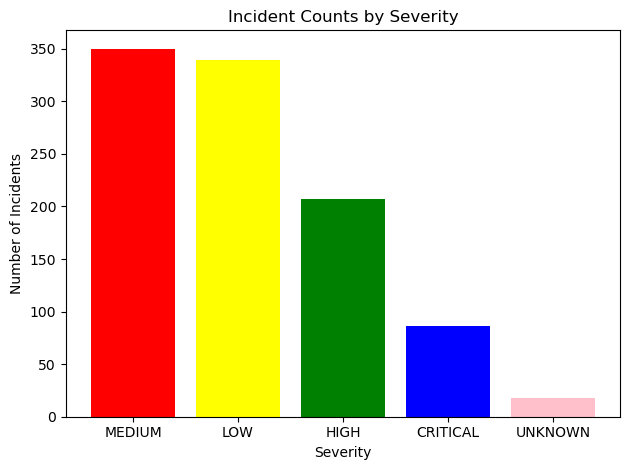

In [100]:
import matplotlib.pyplot as plt

severity_count = df["Severity"].value_counts()
colors=["red","yellow","green","blue","pink"]

plt.bar(severity_count.index, severity_count.values,color=colors)

plt.title("Incident Counts by Severity")
plt.xlabel("Severity")
plt.ylabel("Number of Incidents")

plt.tight_layout()

plt.show()

## Create a line chart showing incident frequency over time. 

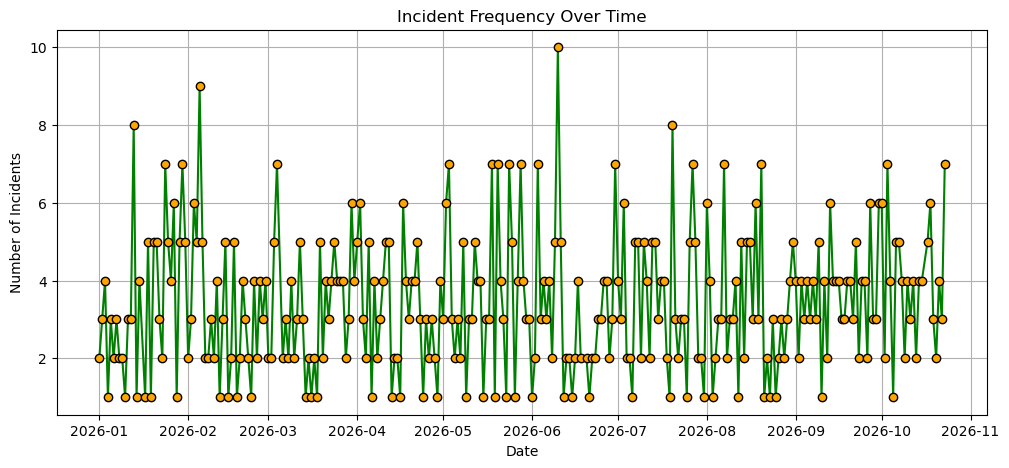

In [87]:
incident_count = df.groupby(df["Timestamp"].dt.date)["Incident ID"].count()
plt.figure(figsize=(12,5))

plt.plot(incident_count.index, incident_count.values,
         marker="o",
         color="green",
         markerfacecolor="orange",
         markeredgecolor="black")

plt.title("Incident Frequency Over Time")
plt.xlabel("Date")
plt.ylabel("Number of Incidents")

plt.xticks(rotation=0)
plt.grid()

plt.show()

# Create a box plot comparing resolution times across severity levels.

<Figure size 1000x500 with 0 Axes>

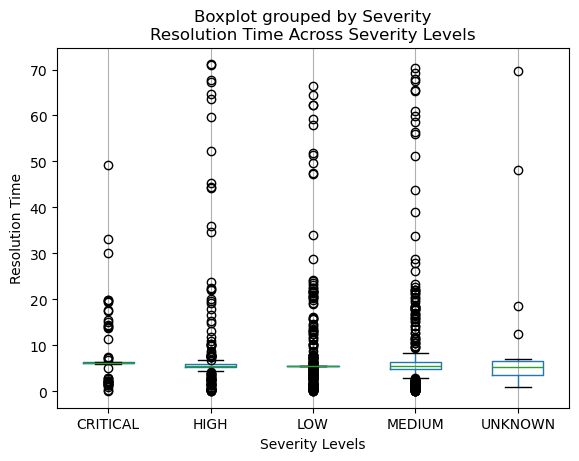

In [88]:
import matplotlib.pyplot as pl
plt.figure(figsize=(10,5))
df.boxplot(column="Resolution Time (Hours)", by="Severity")
plt.title("Resolution Time Across Severity Levels")
plt.xlabel("Severity Levels")
plt.ylabel("Resolution Time")
plt.grid(axis="y")
plt.show()